# Name:Gauri Yadav Shinde
# Roll no: 33

## Practical no 10 
## “Player Performance Prediction using IPL Dataset”

In [14]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns


In [15]:
matches = pd.read_csv('matches.csv')
deliveries = pd.read_csv('deliveries.csv')

print("---- Matches Dataset ----")
display(matches.head(5))
print("\nColumns:", matches.columns.tolist())

print("\n---- Deliveries Dataset ----")
display(deliveries.head(5))
print("\nColumns:", deliveries.columns.tolist())


---- Matches Dataset ----


,id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,target_runs,target_overs,super_over,method,umpire1,umpire2
0,335982,2007/08,Bangalore,2008-04-18,League,BB McCullum,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,runs,140.0,223.0,20.0,N,NaN,Asad Rauf,RE Koertzen
1,335983,2007/08,Chandigarh,2008-04-19,League,MEK Hussey,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,bat,Chennai Super Kings,runs,33.0,241.0,20.0,N,NaN,MR Benson,SL Shastri
2,335984,2007/08,Delhi,2008-04-19,League,MF Maharoof,Feroz Shah Kotla,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,bat,Delhi Daredevils,wickets,9.0,130.0,20.0,N,NaN,Aleem Dar,GA Pratapkumar
3,335985,2007/08,Mumbai,2008-04-20,League,MV Boucher,Wankhede Stadium,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,Royal Challengers Bangalore,wickets,5.0,166.0,20.0,N,NaN,SJ Davis,DJ Harper
4,335986,2007/08,Kolkata,2008-04-20,League,DJ Hussey,Eden Gardens,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,bat,Kolkata Knight Riders,wickets,5.0,111.0,20.0,N,NaN,BF Bowden,K Hariharan



Columns: ['id', 'season', 'city', 'date', 'match_type', 'player_of_match', 'venue', 'team1', 'team2', 'toss_winner', 'toss_decision', 'winner', 'result', 'result_margin', 'target_runs', 'target_overs', 'super_over', 'method', 'umpire1', 'umpire2']

---- Deliveries Dataset ----


,match_id,inning,batting_team,bowling_team,over,ball,batter,bowler,non_striker,batsman_runs,extra_runs,total_runs,extras_type,is_wicket,player_dismissed,dismissal_kind,fielder
0,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,1,SC Ganguly,P Kumar,BB McCullum,0,1,1,legbyes,0,NaN,NaN,NaN
1,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,2,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
2,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,3,BB McCullum,P Kumar,SC Ganguly,0,1,1,wides,0,NaN,NaN,NaN
3,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,4,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
4,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,5,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN



Columns: ['match_id', 'inning', 'batting_team', 'bowling_team', 'over', 'ball', 'batter', 'bowler', 'non_striker', 'batsman_runs', 'extra_runs', 'total_runs', 'extras_type', 'is_wicket', 'player_dismissed', 'dismissal_kind', 'fielder']


In [16]:
deliveries.fillna(0, inplace=True)

batting_stats = deliveries.groupby('batter').agg({
    'batsman_runs':'sum',
    'ball':'count',
    'is_wicket': lambda x: (x==1).sum()
}).rename(columns={
    'batsman_runs':'Total_Runs',
    'ball':'Balls_Faced',
    'is_wicket':'Times_Out'
}).reset_index()
batting_stats['Strike_Rate'] = (batting_stats['Total_Runs'] / batting_stats['Balls_Faced']) * 100

bowling_stats = deliveries.groupby('bowler').agg({
    'total_runs':'sum',
    'is_wicket': lambda x: (x==1).sum(),
    'ball':'count'
}).rename(columns={
    'total_runs':'Runs_Conceded',
    'is_wicket':'Wickets',
    'ball':'Balls_Bowled'
}).reset_index()
bowling_stats['Bowling_Avg'] = bowling_stats['Runs_Conceded'] / bowling_stats['Wickets'].replace(0,1)
bowling_stats['Economy_Rate'] = (bowling_stats['Runs_Conceded'] / bowling_stats['Balls_Bowled']) * 6

player_stats = pd.merge(batting_stats, bowling_stats, left_on='batter', right_on='bowler', how='outer')
player_stats['Player'] = player_stats['batter'].combine_first(player_stats['bowler'])
player_stats.drop(columns=['batter','bowler'], inplace=True)
player_stats.fillna(0, inplace=True)

display(player_stats.head(10))


,Total_Runs,Balls_Faced,Times_Out,Strike_Rate,Runs_Conceded,Wickets,Balls_Bowled,Bowling_Avg,Economy_Rate,Player
0,280.0,196.0,15.0,142.857143,400.0,19.0,270.0,21.052632,8.888889,A Ashish Reddy
1,634.0,505.0,26.0,125.544554,37.0,2.0,25.0,18.500000,8.880000,A Badoni
2,4.0,7.0,1.0,57.142857,245.0,11.0,234.0,22.272727,6.282051,A Chandila
3,53.0,75.0,5.0,70.666667,0.0,0.0,0.0,0.000000,0.000000,A Chopra
4,25.0,20.0,2.0,125.000000,144.0,5.0,108.0,28.800000,8.000000,A Choudhary
5,4.0,5.0,0.0,80.000000,47.0,0.0,25.0,47.000000,11.280000,A Dananjaya
6,62.0,57.0,2.0,108.771930,106.0,2.0,66.0,53.000000,9.636364,A Flintoff
7,2.0,2.0,0.0,100.000000,115.0,2.0,68.0,57.500000,10.147059,A Kamboj
8,35.0,49.0,2.0,71.428571,1089.0,49.0,983.0,22.224490,6.646999,A Kumble
9,231.0,181.0,14.0,127.624309,0.0,0.0,0.0,0.000000,0.000000,A Manohar


In [4]:
player_stats['Performance_Score'] = player_stats['Total_Runs'] + (player_stats['Wickets']*20)

player_stats[['Player','Performance_Score']].head(10)


,Player,Performance_Score
0,A Ashish Reddy,660.0
1,A Badoni,674.0
2,A Chandila,224.0
3,A Chopra,53.0
4,A Choudhary,125.0
5,A Dananjaya,4.0
6,A Flintoff,102.0
7,A Kamboj,42.0
8,A Kumble,1015.0
9,A Manohar,231.0


In [17]:
player_stats['Performance_Score'] = player_stats['Total_Runs'] + (player_stats['Wickets']*20)

player_stats[['Player','Performance_Score']].head(10)


,Player,Performance_Score
0,A Ashish Reddy,660.0
1,A Badoni,674.0
2,A Chandila,224.0
3,A Chopra,53.0
4,A Choudhary,125.0
5,A Dananjaya,4.0
6,A Flintoff,102.0
7,A Kamboj,42.0
8,A Kumble,1015.0
9,A Manohar,231.0


In [18]:
features = ['Total_Runs','Balls_Faced','Times_Out','Strike_Rate',
            'Runs_Conceded','Wickets','Balls_Bowled','Bowling_Avg','Economy_Rate']

X = player_stats[features]
y = np.log1p(player_stats['Performance_Score'])  # log-transform for skewed target

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)


In [19]:
X_train

array([[-0.14994878, -0.05490535,  0.07143912, ..., -0.52700241,
        -1.13689277, -1.42941366],
       [-0.1201393 , -0.26703452, -0.29987522, ..., -0.52700241,
        -1.13689277, -1.42941366],
       [-0.36755805, -0.36921869, -0.45458954, ..., -0.51665303,
        -0.85214875, -0.28722012],
       ...,
       [-0.43015797, -0.4390661 , -0.4855324 , ..., -0.41463771,
         0.98286827,  0.9200985 ],
       [-0.44804366, -0.44423998, -0.51647526, ..., -0.44272888,
         0.73767203,  0.41746654],
       [ 0.57939002,  0.53491721,  0.10238198, ..., -0.52700241,
        -1.13689277, -1.42941366]], shape=(585, 9))

In [20]:
X_test

array([[-0.43810717, -0.4390661 , -0.51647526, ..., -0.23869824,
        -0.02428187,  0.01248366],
       [-0.32880571, -0.34334928, -0.33081809, ..., -0.52700241,
        -1.13689277, -1.42941366],
       [-0.39736753, -0.39250116, -0.39270381, ..., -0.52700241,
        -1.13689277, -1.42941366],
       ...,
       [-0.43512622, -0.44035957, -0.42364667, ...,  0.15014277,
         0.99868738,  0.66543913],
       [ 1.10204971,  1.15190266,  1.58763937, ...,  4.34607729,
        -0.11988433,  0.36404275],
       [-0.44804366, -0.4610551 , -0.54741812, ..., -0.49891123,
         0.47665668,  0.95516584]], shape=(147, 9))

In [21]:
X_train.shape

(585, 9)

In [22]:
y_train

683    5.707110
250    5.802118
336    4.624973
260    6.715383
439    3.295837
         ...   
71     6.429719
106    7.349874
270    4.369448
435    3.713572
102    6.942157
Name: Performance_Score, Length: 585, dtype: float64

In [23]:
y_test

604    5.252273
33     4.795791
300    3.951244
457    4.852030
634    3.258097
         ...   
70     0.693147
192    2.639057
328    5.811141
165    8.648397
135    0.000000
Name: Performance_Score, Length: 147, dtype: float64

In [24]:
y_train.shape

(585,)

In [28]:
rf = RandomForestRegressor(n_estimators=500, max_depth=10, random_state=42)
rf.fit(X_train, y_train)

y_pred_log = rf.predict(X_test)
y_pred = np.expm1(y_pred_log)  
y_true = np.expm1(y_test)

# Accuracy metrics
mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))  
r2 = r2_score(y_true, y_pred)

print("---- Player Performance Prediction Accuracy ----")
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R² Score: {r2:.2f} (~{r2*100:.2f}% accuracy)")


---- Player Performance Prediction Accuracy ----
MAE: 69.90
RMSE: 211.66
R² Score: 0.97 (~97.08% accuracy)


In [29]:
kmeans = KMeans(n_clusters=3, random_state=42)
clusters = kmeans.fit_predict(X_scaled)
player_stats['Performance_Cluster'] = clusters

sil_score = silhouette_score(X_scaled, clusters)
print(f"Player Clustering Silhouette Score: {sil_score:.2f}")

cluster_stats = player_stats.groupby('Performance_Cluster')['Performance_Score'].mean()
print("\nAverage Performance Score per cluster:")
print(cluster_stats)


Player Clustering Silhouette Score: 0.49

Average Performance Score per cluster:
Performance_Cluster
0     337.129139
1    3492.724138
2    2612.285714
Name: Performance_Score, dtype: float64


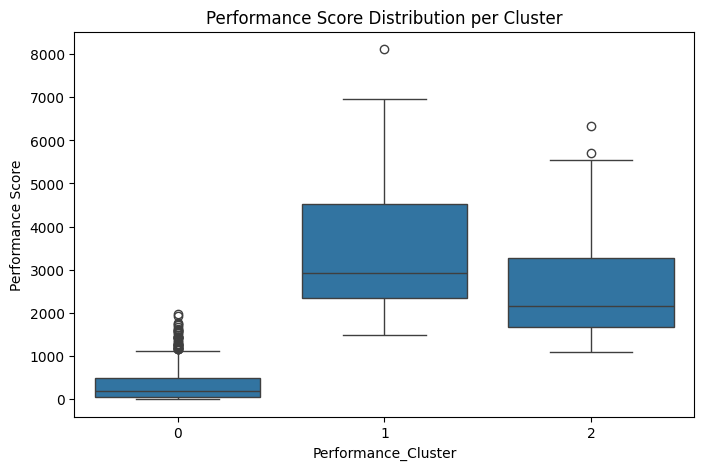

In [30]:
plt.figure(figsize=(8,5))
sns.boxplot(x='Performance_Cluster', y='Performance_Score', data=player_stats)
plt.title('Performance Score Distribution per Cluster')
plt.ylabel('Performance Score')
plt.show()


C:\Users\DELL\AppData\Local\Temp\ipykernel_8604\1566313730.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feat_importance_df, palette='viridis')


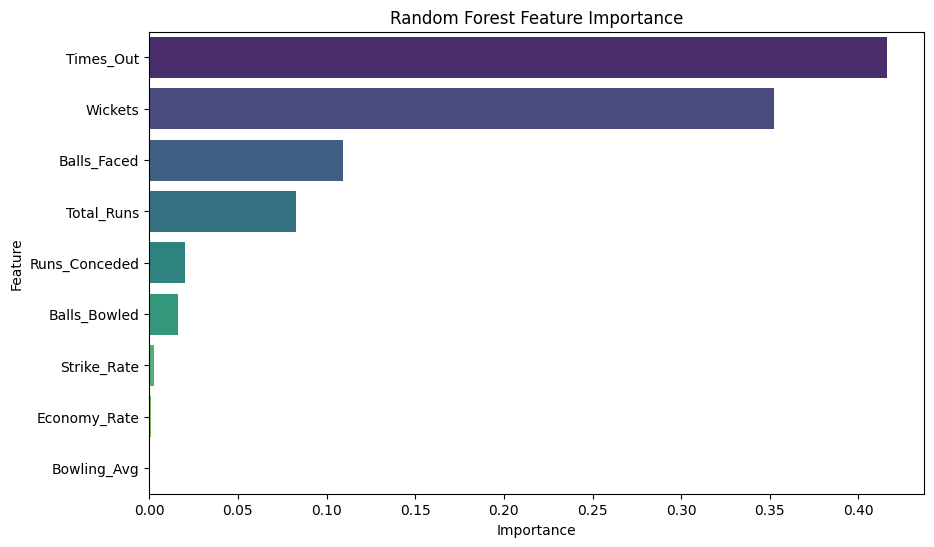

Feature Importances:
         Feature  Importance
2      Times_Out    0.416291
5        Wickets    0.352158
1    Balls_Faced    0.109434
0     Total_Runs    0.082675
4  Runs_Conceded    0.019876
6   Balls_Bowled    0.015946
3    Strike_Rate    0.002446
8   Economy_Rate    0.000810
7    Bowling_Avg    0.000364


In [32]:
importances = rf.feature_importances_
feature_names = features

feat_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10,6))
sns.barplot(x='Importance', y='Feature', data=feat_importance_df, palette='viridis')
plt.title('Random Forest Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()

print("Feature Importances:")
print(feat_importance_df)


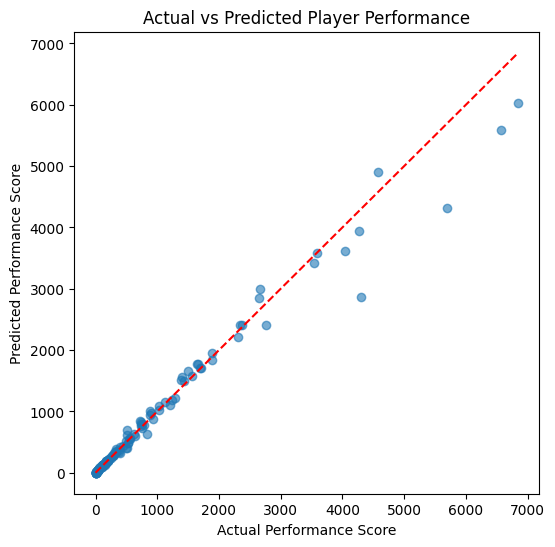

In [33]:
plt.figure(figsize=(6,6))
plt.scatter(y_true, y_pred, alpha=0.6)
plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], 'r--')  # ideal line
plt.xlabel("Actual Performance Score")
plt.ylabel("Predicted Performance Score")
plt.title("Actual vs Predicted Player Performance")
plt.show()


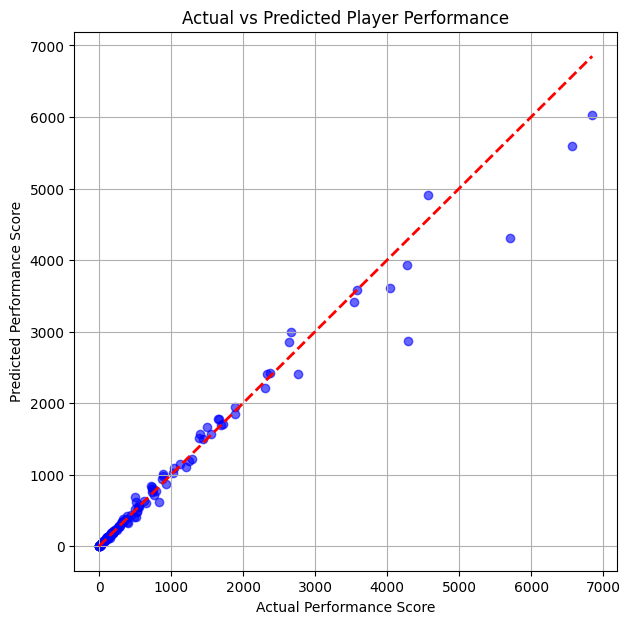

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,7))
plt.scatter(y_true, y_pred, alpha=0.6, color='blue')
plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], 'r--', linewidth=2)  # ideal line
plt.xlabel("Actual Performance Score")
plt.ylabel("Predicted Performance Score")
plt.title("Actual vs Predicted Player Performance")
plt.grid(True)
plt.show()

In [37]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred_log = rf.predict(X_test)
y_pred = np.expm1(y_pred_log)  
y_true = np.expm1(y_test)

mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
r2 = r2_score(y_true, y_pred)

print("---- Player Performance Prediction Accuracy ----")
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R² Score: {r2:.2f} (~{r2*100:.2f}% accuracy)")


---- Player Performance Prediction Accuracy ----
MAE: 69.90
RMSE: 211.66
R² Score: 0.97 (~97.08% accuracy)
